# Classification Images Fruits-360

## 0. General Part

In [17]:
import copy
import random
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm.notebook import tqdm
from torchvision import datasets, models
from torchvision.models import resnet18, ResNet18_Weights

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


In [18]:
# hyperparameters
N_TRAIN = 0.8
IMG_SIZE = 100
BATCH_SIZE = 64

N_EPOCHS = 20
PATIENCE_LOSS = 5
MIN_DELTA = 1e-4

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
PATIENCE_LR = 3
FACTOR_LR = 0.1

TRAIN_DIR = "Training"
TEST_DIR = "Test"

In [19]:
# load dataset
train_idx = datasets.ImageFolder(root=TRAIN_DIR)
test_idx = datasets.ImageFolder(root=TEST_DIR)

# different names
train_cls = set(train_idx.classes)
test_cls = set(test_idx.classes)
print("only in training:")
print(sorted(train_cls - test_cls))
print("only in test:")
print(sorted(test_cls - train_cls))

train_to_test_idx = {}
for name, old_idx in train_idx.class_to_idx.items():
    if name == "BlackBerry 4":
        name = "Blackberry 4"

    new_idx = test_idx.class_to_idx[name]
    train_to_test_idx[old_idx] = new_idx


only in training:
['BlackBerry 4']
only in test:
['Blackberry 4']


In [20]:
all_train_samples = [
    (image_path, train_to_test_idx[label])
    for image_path, label in train_idx.samples
]
test_samples = list(test_idx.samples)
cls_names = list(test_idx.classes)
cls_to_idx = dict(test_idx.class_to_idx)
num_cls = len(cls_names)

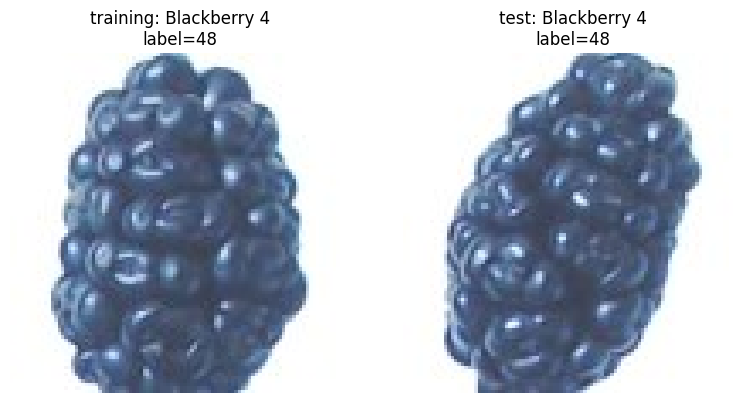

In [21]:
# example
cls_name = "Blackberry 4"
label = cls_to_idx[cls_name]

train_path = next(path for path, y in all_train_samples if y == label)
test_path = next(path for path, y in test_samples if y == label)

plt.figure(figsize=(8, 4))

for i, (title, path) in enumerate([
    ("training", train_path),
    ("test", test_path),
]):
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 2, i + 1)
    plt.imshow(image)
    plt.title(f"{title}: {cls_name}\nlabel={label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
# Dataset
class FruitDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label = self.samples[idx]
        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = self.transform(image=image)["image"]

        return image, label


In [23]:
# transform
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std =(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std =(0.229, 0.224, 0.225)),
    ToTensorV2()
])

In [24]:
# DataLoader
train_samples, val_samples = train_test_split(
    all_train_samples,
    train_size=N_TRAIN,
    random_state=SEED,
    stratify=[label for _, label in all_train_samples],
)

train_dataset = FruitDataset(
    samples=train_samples,
    transform=train_transform,
)
val_dataset = FruitDataset(
    samples=val_samples,
    transform=val_transform,
)
test_dataset = FruitDataset(
    samples=test_samples,
    transform=val_transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)


In [25]:
# early stop
class EarlyStopper:
    def __init__(self, patience=PATIENCE_LOSS, min_delta=MIN_DELTA):
        self.patience = patience
        self.min_delta = min_delta

        self.best_val_loss = float("inf")
        self.counter = 0
        self.stopped_epoch = None

    def step(self, val_loss, epoch):
        if val_loss < self.best_val_loss - self.min_delta:
            self.best_val_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1

        should_stop = self.counter >= self.patience
        if should_stop:
            self.stopped_epoch = epoch

        return should_stop


In [30]:
# train
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_labels = []
    all_pred = []

    for x, y in tqdm(loader, desc="Evaluate", leave=False):
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)
        pred = logits.argmax(dim=1)
        batch_size = y.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (pred == y).sum().item()
        total_samples += batch_size

        all_labels.extend(y.cpu().tolist())
        all_pred.extend(pred.cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        "acc": total_correct / total_samples,
        "f1_macro": f1_score(
            all_labels,
            all_pred,
            labels=list(range(num_cls)),
            average="macro",
            zero_division=0,
        ),
    }

def train(
    model,
    optimizer,
    scheduler,
    train_loader,
    val_loader,
    criterion,
    best_model_path,
    n_epochs,
    frozen_backbone=False,
):
    stopper = EarlyStopper()
    model.to(device)

    best_f1 = float("-inf")
    best_f1_epoch = None
    best_state = None
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_f1_macro": [],
    }

    for epoch in range(1, n_epochs + 1):
        model.train()
        if frozen_backbone:
            model.eval()
            model.fc.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for x, y in tqdm(
            train_loader,
            desc=f"Epoch {epoch}/{n_epochs}",
            leave=False,
        ):
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            logits = model(x)
            loss = criterion(logits, y)
            
            loss.backward()
            optimizer.step()

            pred = logits.argmax(dim=1)
            batch_size = y.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (pred == y).sum().item()
            total_samples += batch_size

        train_loss = total_loss / total_samples
        train_acc = total_correct / total_samples
        val_metrics = evaluate(model, val_loader, criterion)
        val_loss = val_metrics["loss"]
        val_acc = val_metrics["acc"]
        val_f1_macro = val_metrics["f1_macro"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1_macro"].append(val_f1_macro)

        if scheduler is not None:
            scheduler.step(val_loss)

        is_best = val_f1_macro > best_f1
        if is_best:
            best_f1 = val_f1_macro
            best_f1_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": (
                        scheduler.state_dict()
                        if scheduler is not None
                        else None
                    ),
                    "val_loss": val_loss,
                    "val_acc": val_acc,
                    "val_f1_macro": val_f1_macro,
                    "class_to_idx": cls_to_idx,
                    "history": copy.deepcopy(history),
                },
                best_model_path,
            )

        print(
            f"epoch {epoch:>2}/{n_epochs} | "
            f"{train_loss=:=.4f} | "
            f"{val_loss=:.4f} | "
            f"{train_acc=:.4f} | "
            f"{val_acc=:.4f} | "
            f"{val_f1_macro=:.4f}"
        )
        
        should_stop = stopper.step(val_loss, epoch)
        if should_stop:
            print(
                f"Early stopping at epoch {epoch}: "
            )
            break

    if best_state is not None:
        model.load_state_dict(best_state)
        print(
            f"{best_f1_epoch=}: "
            f"val_f1_macro={best_f1:.4f}"
        )

    return history


In [31]:
# visualisation
def plot_curves(history, title, metric):
    epochs = range(1, len(history[f"train_{metric}"]) + 1)

    plt.figure(figsize=(7, 4.5))
    plt.plot(epochs, history[f"train_{metric}"], label="train")
    plt.plot(epochs, history[f"val_{metric}"], label="val", linestyle="--")

    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 1. Custom CNN

In [32]:
# custom architecture
class FruitCNN(nn.Module):
    def __init__(self, num_cls):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(32 * 4 * 4, num_cls),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

custom_model = FruitCNN(num_cls=num_cls).to(device)

print(custom_model)
print(
    "learning parametres:",
    sum(p.numel() for p in custom_model.parameters() if p.requires_grad),
)


FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=512, out_features=278, bias=True)
  )
)
learning parametres: 147702


In [33]:
# custom learning
сustom_optimizer = torch.optim.Adam(
    custom_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

custom_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    сustom_optimizer,
    mode="min",
    factor=FACTOR_LR,
    patience=PATIENCE_LR,
)

custom_history = train(
    model=custom_model,
    optimizer=сustom_optimizer,
    scheduler=custom_scheduler,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    best_model_path="best_custom.pth",
    n_epochs=N_EPOCHS,
)


Epoch 1/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch  1/20 | train_loss=3.3975 | val_loss=1.6943 | train_acc=0.2221 | val_acc=0.6352 | val_f1_macro=0.6098


Epoch 2/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch  2/20 | train_loss=1.8168 | val_loss=1.0553 | train_acc=0.4940 | val_acc=0.7624 | val_f1_macro=0.7595


... (50 outputs left out)

epoch 19/20 | train_loss=0.2128 | val_loss=0.1061 | train_acc=0.9281 | val_acc=0.9698 | val_f1_macro=0.9713


Epoch 20/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 20/20 | train_loss=0.2055 | val_loss=0.1005 | train_acc=0.9297 | val_acc=0.9703 | val_f1_macro=0.9719
best_f1_epoch=20: val_f1_macro=0.9719


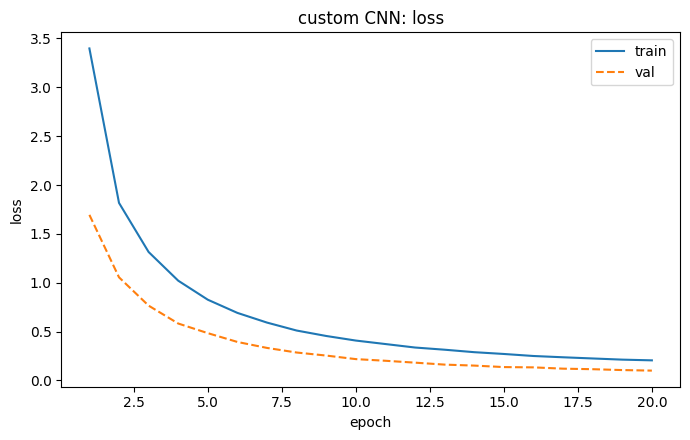

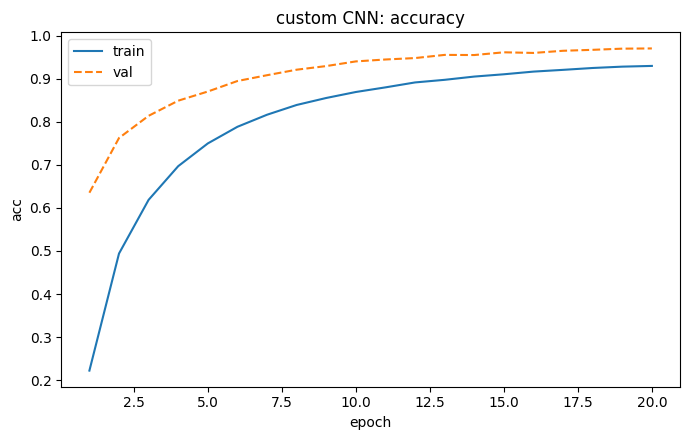

In [34]:
# custom visualisation
plot_curves(
    custom_history,
    title="custom CNN: loss",
    metric="loss",
)
plot_curves(
    custom_history,
    title="custom CNN: accuracy",
    metric="acc",
)


In [36]:
# custom inference
custom_test_metrics = evaluate(
    model=custom_model,
    loader=test_loader,
    criterion=criterion,
)

print(f"accuracy: {custom_test_metrics['acc']:.4f}")
print(f"f1_macro: {custom_test_metrics['f1_macro']:.4f}")


Evaluate:   0%|          | 0/778 [00:00<?, ?it/s]

accuracy: 0.9493
f1_macro: 0.9478


## 2. ResNet CNN

In [37]:
# ResNet architecture
resnet_model = resnet18(
    weights=ResNet18_Weights.DEFAULT,
)
for param in resnet_model.parameters():
    param.requires_grad = False
    
resnet_model.fc = nn.Linear(
    in_features=resnet_model.fc.in_features,
    out_features=num_cls,
)

resnet_model = resnet_model.to(device)
print(resnet_model)
print(
    "learning parametres:",
    sum(p.numel() for p in resnet_model.parameters() if p.requires_grad),
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 233MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [40]:
# ResNet learning
resnet_optimizer = torch.optim.Adam(
    resnet_model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

resnet_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=FACTOR_LR,
    patience=PATIENCE_LR,
)

resnet_history = train(
    model=resnet_model,
    optimizer=resnet_optimizer,
    scheduler=resnet_scheduler,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    best_model_path="best_resnet.pth",
    n_epochs=N_EPOCHS,
    frozen_backbone=True,
)


Epoch 1/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch  1/20 | train_loss=0.0320 | val_loss=0.0319 | train_acc=0.9973 | val_acc=0.9969 | val_f1_macro=0.9974


Epoch 2/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch  2/20 | train_loss=0.0267 | val_loss=0.0277 | train_acc=0.9978 | val_acc=0.9969 | val_f1_macro=0.9974


... (50 outputs left out)

epoch 19/20 | train_loss=0.0069 | val_loss=0.0084 | train_acc=0.9995 | val_acc=0.9991 | val_f1_macro=0.9993


Epoch 20/20:   0%|          | 0/1869 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 20/20 | train_loss=0.0065 | val_loss=0.0081 | train_acc=0.9997 | val_acc=0.9993 | val_f1_macro=0.9994
best_f1_epoch=20: val_f1_macro=0.9994


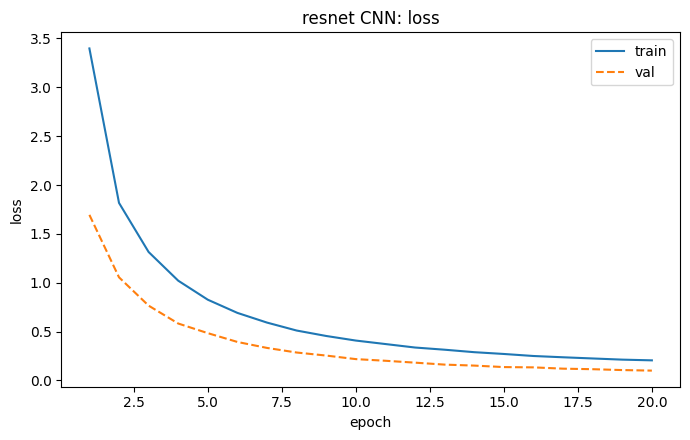

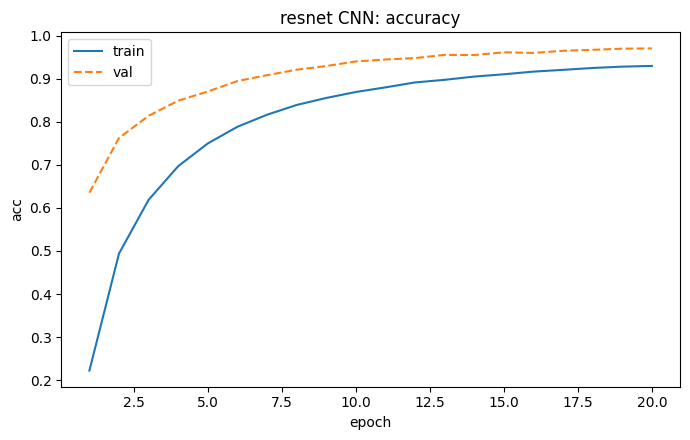

In [41]:
# ResNet visualisation
plot_curves(
    custom_history,
    title="resnet CNN: loss",
    metric="loss",
)
plot_curves(
    custom_history,
    title="resnet CNN: accuracy",
    metric="acc",
)


In [42]:
# ResNet inference
resnet_test_metrics = evaluate(
    model=resnet_model,
    loader=test_loader,
    criterion=criterion,
)

print(f"accuracy: {resnet_test_metrics['acc']:.4f}")
print(f"f1_macro: {resnet_test_metrics['f1_macro']:.4f}")


Evaluate:   0%|          | 0/778 [00:00<?, ?it/s]

accuracy: 0.9877
f1_macro: 0.9877


In [44]:
print(f"custom accuracy: {custom_test_metrics['acc']:.4f}")
print(f"custom f1_macro: {custom_test_metrics['f1_macro']:.4f}")
print(f"resnet accuracy: {resnet_test_metrics['acc']:.4f}")
print(f"resnet f1_macro: {resnet_test_metrics['f1_macro']:.4f}")


custom accuracy: 0.9493
custom f1_macro: 0.9478
resnet accuracy: 0.9877
resnet f1_macro: 0.9877


## Вывод
Преимущество ResNet18 согласуется с использованием transfer learning: предобученная свёрточная часть предоставляет признаки, на основе которых настраивается новый классификатор. Собственная CNN также показала высокое качество, несмотря на простую архитектуру из двух свёрточных слоёв. Её обучающие и валидационные метрики постепенно улучшались; выраженного ухудшения validation loss к концу обучения не наблюдалось.